# Computer Vision Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Name:** Haider  |  **Reg No:** FA23-BAI-015  |  **Dataset:** BloodMNIST (size 64)

**Plan:** (1) set personal settings from my registration number, (2) build a small balanced subset, (3) HOG + LinearSVC, (4) SIFT (fixed grid) + LinearSVC, (5) test both models on clean / rotated / noisy test images, (6) short answers.

## Personal settings (first cell)

In [1]:
REG = "FA23-BAI-015"

digits = "".join(ch for ch in REG if ch.isdigit())
SEED = int(digits[-2:])
last = int(digits[-1])

HOG_CELL  = 8 if last % 2 == 0 else 16
SIFT_GRID = 4 if last <= 4 else 6

print("Registration no :", REG)
print("Last digit      :", last)
print("Random seed     :", SEED)
print(f"HOG cell size   : {HOG_CELL} x {HOG_CELL}")
print(f"SIFT grid       : {SIFT_GRID} x {SIFT_GRID} ({SIFT_GRID**2} keypoints)")

Registration no : FA23-BAI-015
Last digit      : 5
Random seed     : 15
HOG cell size   : 16 x 16
SIFT grid       : 6 x 6 (36 keypoints)


In [2]:

!pip install -q kagglehub medmnist opencv-python scikit-image scikit-learn pandas matplotlib

In [3]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")
np.random.seed(SEED)
print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


## Q1. Data setup (3 marks)

In [4]:
import kagglehub


path = kagglehub.dataset_download("flyt007/bloodmnist")

print("Path to dataset files:", path)

100%|██████████| 898M/898M [00:10<00:00, 87.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/flyt007/bloodmnist/versions/1


In [5]:
def load_bloodmnist(path):
    """Find the BloodMNIST .npz in the Kaggle folder. If it is missing (or is not size 64),
    fall back to the official medmnist package with size=64."""
    files = glob.glob(os.path.join(path, "**", "*.npz"), recursive=True)
    files = sorted(files, key=lambda f: (("64" not in os.path.basename(f)), f))
    data = None
    if files:
        print("Using file:", files[0])
        z = np.load(files[0])
        data = {k: z[k] for k in z.files}
    if data is None or data["train_images"].shape[1] != 64:
        print("Kaggle copy is missing or not 64x64 -> trying medmnist size=64 ...")
        try:
            from medmnist import BloodMNIST
            data = {}
            for s in ["train", "val", "test"]:
                ds = BloodMNIST(split=s, download=True, size=64)
                data[f"{s}_images"], data[f"{s}_labels"] = ds.imgs, ds.labels
        except Exception as e:
            print("medmnist fallback failed:", e, "-> continuing with the Kaggle file as it is")
    return data

data = load_bloodmnist(path)
for k, v in data.items():
    print(f"{k:14s}", v.shape, v.dtype)

Kaggle copy is missing or not 64x64 -> trying medmnist size=64 ...


100%|██████████| 156M/156M [01:43<00:00, 1.52MB/s]


train_images   (11959, 64, 64, 3) uint8
train_labels   (11959, 1) uint8
val_images     (1712, 64, 64, 3) uint8
val_labels     (1712, 1) uint8
test_images    (3421, 64, 64, 3) uint8
test_labels    (3421, 1) uint8


In [6]:
CLASS_IDS   = [1, 5, 6, 7]
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}

rng = np.random.RandomState(SEED)

def take_subset(images, labels, n_per_class):
    labels = labels.ravel()
    X, y = [], []
    for new_label, cls in enumerate(CLASS_IDS):
        idx = np.where(labels == cls)[0]
        pick = rng.choice(idx, n_per_class, replace=False)
        X.append(images[pick]); y.append(np.full(n_per_class, new_label))
    return np.concatenate(X), np.concatenate(y)

def to_gray_128(imgs):
    out = []
    for im in imgs:
        g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY) if im.ndim == 3 else im
        out.append(cv2.resize(g, (128, 128), interpolation=cv2.INTER_LINEAR))
    return np.array(out, dtype=np.uint8)

raw, Xg, Y = {}, {}, {}
for s in ["train", "val", "test"]:
    raw[s], Y[s] = take_subset(data[f"{s}_images"], data[f"{s}_labels"], N_PER_CLASS[s])
    Xg[s] = to_gray_128(raw[s])

for s in ["train", "val", "test"]:
    counts = {CLASS_NAMES[i]: int((Y[s] == i).sum()) for i in range(4)}
    print(f"{s:5s} | raw {raw[s].shape} -> gray128 {Xg[s].shape} | labels {Y[s].shape} | class counts {counts}")

train | raw (400, 64, 64, 3) -> gray128 (400, 128, 128) | labels (400,) | class counts {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   | raw (120, 64, 64, 3) -> gray128 (120, 128, 128) | labels (120,) | class counts {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  | raw (120, 64, 64, 3) -> gray128 (120, 128, 128) | labels (120,) | class counts {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


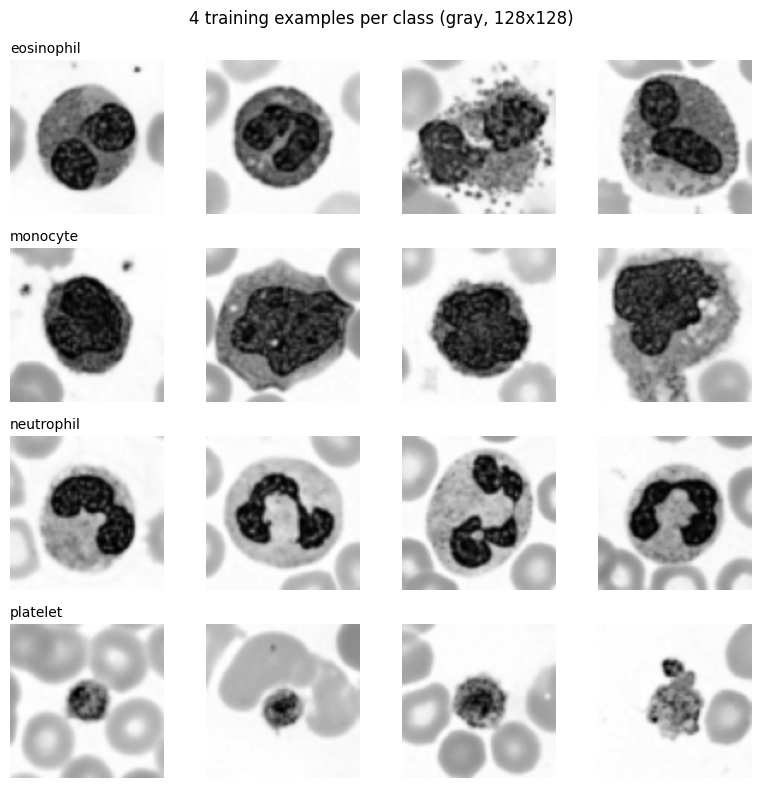

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    idx = np.where(Y["train"] == r)[0][:4]
    for c, i in enumerate(idx):
        axes[r, c].imshow(Xg["train"][i], cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(CLASS_NAMES[r], fontsize=10, loc="left")
plt.suptitle("4 training examples per class (gray, 128x128)"); plt.tight_layout(); plt.show()

## Q2. HOG + SVM (6 marks)

In [8]:
def hog_feat(img, vis=False):
    return hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True, visualize=vis)

cells = 128 // HOG_CELL
blocks = cells - 2 + 1
by_hand = blocks * blocks * 2 * 2 * 9
print(f"cells per side = {cells}, blocks per side = {blocks}, by-hand length = {blocks}*{blocks}*2*2*9 = {by_hand}")

f = hog_feat(Xg["train"][0])
print("Actual HOG feature length from skimage:", f.shape[0])
assert f.shape[0] == by_hand

cells per side = 8, blocks per side = 7, by-hand length = 7*7*2*2*9 = 1764
Actual HOG feature length from skimage: 1764


In [9]:
Xh = {s: np.array([hog_feat(im) for im in Xg[s]]) for s in ["train", "val", "test"]}
print({s: Xh[s].shape for s in Xh})

{'train': (400, 1764), 'val': (120, 1764), 'test': (120, 1764)}


### Q2(b) HOG picture (one image per class)

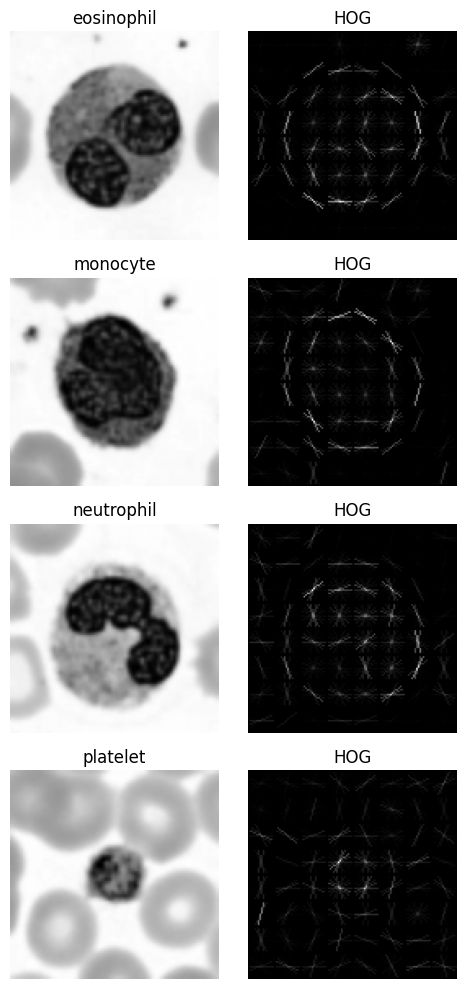

In [10]:
fig, axes = plt.subplots(4, 2, figsize=(5, 10))
for r in range(4):
    i = np.where(Y["train"] == r)[0][0]
    _, hog_img = hog_feat(Xg["train"][i], vis=True)
    axes[r, 0].imshow(Xg["train"][i], cmap="gray"); axes[r, 0].set_title(CLASS_NAMES[r]); axes[r, 0].axis("off")
    axes[r, 1].imshow(exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-9)), cmap="gray")
    axes[r, 1].set_title("HOG"); axes[r, 1].axis("off")
plt.tight_layout(); plt.show()

### Q2(c) Train LinearSVC (C chosen on validation only)

   C  val_acc  val_macro_F1
 0.1 0.725000      0.724028
 1.0 0.708333      0.709162
10.0 0.708333      0.709162
Chosen C for HOG: 0.1
HOG + SVM (validation): accuracy = 0.7250 | macro-F1 = 0.7240
Confusion matrix (rows = true, cols = predicted):
 [[16  9  5  0]
 [ 6 21  2  1]
 [ 8  2 20  0]
 [ 0  0  0 30]]


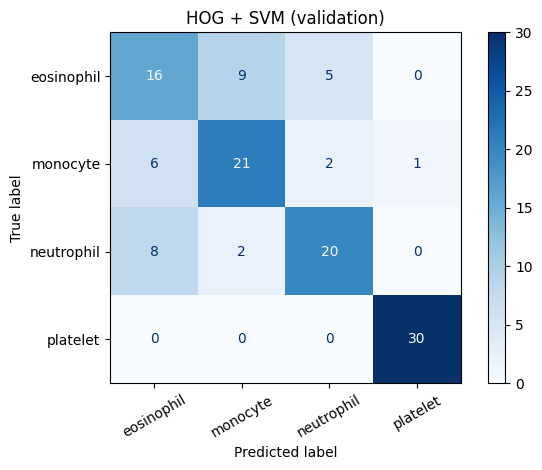

In [11]:
def train_choose_C(Xtr, ytr, Xva, yva, Cs=(0.1, 1, 10)):
    rows, best = [], None
    for Cval in Cs:
        clf = LinearSVC(C=Cval, random_state=SEED, max_iter=20000).fit(Xtr, ytr)
        pred = clf.predict(Xva)
        acc, f1 = accuracy_score(yva, pred), f1_score(yva, pred, average="macro")
        rows.append({"C": Cval, "val_acc": acc, "val_macro_F1": f1})
        if best is None or acc > best[1]:                    )
            best = (Cval, acc, clf)
    return best[2], best[0], pd.DataFrame(rows)

def report(clf, X, y, title):
    pred = clf.predict(X)
    acc, f1 = accuracy_score(y, pred), f1_score(y, pred, average="macro")
    cm = confusion_matrix(y, pred)
    print(f"{title}: accuracy = {acc:.4f} | macro-F1 = {f1:.4f}")
    print("Confusion matrix (rows = true, cols = predicted):\n", cm)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(title); plt.tight_layout(); plt.show()
    return cm

hog_clf, hog_C, hog_table = train_choose_C(Xh["train"], Y["train"], Xh["val"], Y["val"])
print(hog_table.to_string(index=False)); print("Chosen C for HOG:", hog_C)
cm_hog = report(hog_clf, Xh["val"], Y["val"], "HOG + SVM (validation)")

## Q3. SIFT + SVM (7 marks)

### Q3(a) Normal SIFT detection

In [12]:
sift = cv2.SIFT_create()
kp_counts, kp_store = [], []
for im in Xg["train"]:
    kps, des = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps)); kp_store.append(kps)
kp_counts = np.array(kp_counts)
print(f"Keypoints per image  -> average: {kp_counts.mean():.2f} | min: {kp_counts.min()} | max: {kp_counts.max()}")
print("Images with zero keypoints:", int((kp_counts == 0).sum()), "out of", len(kp_counts))

Keypoints per image  -> average: 73.00 | min: 8 | max: 189
Images with zero keypoints: 0 out of 400


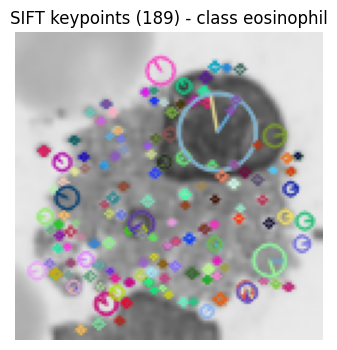

In [13]:
i = int(np.argmax(kp_counts))
vis = cv2.drawKeypoints(Xg["train"][i], kp_store[i], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4, 4)); plt.imshow(vis); plt.axis("off")
plt.title(f"SIFT keypoints ({len(kp_store[i])}) - class {CLASS_NAMES[Y['train'][i]]}"); plt.show()

### Q3(b) Fix: fixed grid of keypoints + `sift.compute`

Number of grid keypoints: 36
Grid centres (x) : [ 10.7  32.   53.3  74.7  96.  117.3]
SIFT feature length: 4608 | by hand: 36 x 128 = 4608


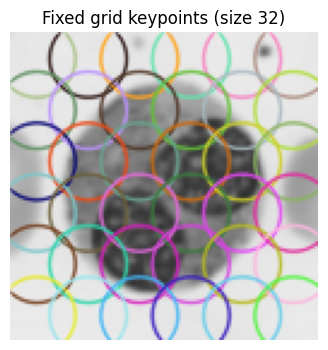

In [14]:
def make_grid_keypoints(n, size=128, kp_size=32):
    step = size / n
    centers = (np.arange(n) + 0.5) * step
    return [cv2.KeyPoint(float(x), float(y), float(kp_size)) for y in centers for x in centers]

GRID_KPS = make_grid_keypoints(SIFT_GRID)
print("Number of grid keypoints:", len(GRID_KPS))
print("Grid centres (x) :", np.round((np.arange(SIFT_GRID) + 0.5) * 128 / SIFT_GRID, 1))

def sift_feat(img):
    _, des = sift.compute(img, GRID_KPS)
    assert des.shape == (SIFT_GRID ** 2, 128), des.shape
    return des.flatten()

f = sift_feat(Xg["train"][0])
print("SIFT feature length:", f.shape[0], "| by hand:", SIFT_GRID**2, "x 128 =", SIFT_GRID**2 * 128)

chk = cv2.drawKeypoints(Xg["train"][0], GRID_KPS, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4, 4)); plt.imshow(chk); plt.axis("off"); plt.title("Fixed grid keypoints (size 32)"); plt.show()

In [15]:
Xs = {s: np.array([sift_feat(im) for im in Xg[s]]) for s in ["train", "val", "test"]}
print({s: Xs[s].shape for s in Xs})

{'train': (400, 4608), 'val': (120, 4608), 'test': (120, 4608)}


### Q3(c) Train LinearSVC (C chosen on validation only)

   C  val_acc  val_macro_F1
 0.1 0.791667      0.786267
 1.0 0.783333      0.780432
10.0 0.808333      0.805436
Chosen C for SIFT: 10
SIFT (grid) + SVM (validation): accuracy = 0.8083 | macro-F1 = 0.8054
Confusion matrix (rows = true, cols = predicted):
 [[18  8  4  0]
 [ 7 22  0  1]
 [ 2  1 27  0]
 [ 0  0  0 30]]


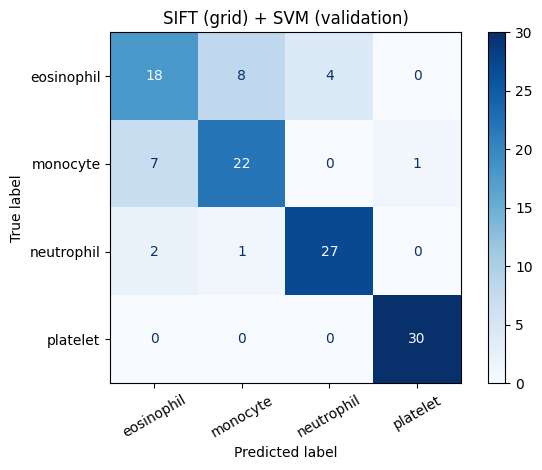

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

def scale_sift(X):
    return X / 512.0

def train_choose_C_sift(Xtr, ytr, Xva, yva, Cs=(0.1, 1, 10)):
    rows, best = [], None
    for Cval in Cs:
        clf = make_pipeline(
            FunctionTransformer(scale_sift),
            LinearSVC(C=Cval, random_state=SEED, max_iter=5000)
        ).fit(Xtr, ytr)
        pred = clf.predict(Xva)
        acc, f1 = accuracy_score(yva, pred), f1_score(yva, pred, average="macro")
        rows.append({"C": Cval, "val_acc": acc, "val_macro_F1": f1})
        if best is None or acc > best[1]:
            best = (Cval, acc, clf)
    return best[2], best[0], pd.DataFrame(rows)

sift_clf, sift_C, sift_table = train_choose_C_sift(Xs["train"], Y["train"], Xs["val"], Y["val"])
print(sift_table.to_string(index=False)); print("Chosen C for SIFT:", sift_C)
cm_sift = report(sift_clf, Xs["val"], Y["val"], "SIFT (grid) + SVM (validation)")

## Q4. Robustness (6 marks)

In [18]:
PREDICTION = {"rotation": "HOG", "noise": "HOG"}
print(PREDICTION)

{'rotation': 'HOG', 'noise': 'HOG'}


### Q4(b) Test-set evaluation with frozen models (clean / rotated 20 deg / noisy sigma = 0.05)

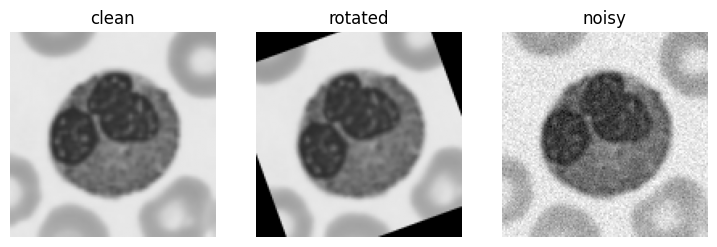

,Clean accuracy,Rotated accuracy,Noisy accuracy
Model,,,
HOG + SVM,0.7500,0.5333,0.4417
SIFT + SVM,0.7833,0.4917,0.8000


In [19]:
def rotate20(img):
    M = cv2.getRotationMatrix2D((64, 64), 20, 1.0)
    return cv2.warpAffine(img, M, (128, 128), flags=cv2.INTER_LINEAR, borderValue=0)

noise_rng = np.random.RandomState(SEED)
def add_noise(img, sigma=0.05):
    x = img.astype(np.float32) / 255.0
    x = np.clip(x + noise_rng.normal(0, sigma, x.shape), 0, 1)
    return (x * 255).round().astype(np.uint8)

test_sets = {
    "clean":   Xg["test"],
    "rotated": np.array([rotate20(im) for im in Xg["test"]]),
    "noisy":   np.array([add_noise(im) for im in Xg["test"]]),
}


fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (name, arr) in zip(axes, test_sets.items()):
    ax.imshow(arr[0], cmap="gray", vmin=0, vmax=255); ax.set_title(name); ax.axis("off")
plt.show()

results = {"HOG + SVM": {}, "SIFT + SVM": {}}
for case, imgs in test_sets.items():
    Fh = np.array([hog_feat(im) for im in imgs])
    Fs = np.array([sift_feat(im) for im in imgs])
    results["HOG + SVM"][case]  = accuracy_score(Y["test"], hog_clf.predict(Fh))
    results["SIFT + SVM"][case] = accuracy_score(Y["test"], sift_clf.predict(Fs))

table = pd.DataFrame(results).T[["clean", "rotated", "noisy"]]
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
table.index.name = "Model"
display(table.round(4))

### Q4(c) Was my prediction correct?

In [20]:
drop = pd.DataFrame({
    "rotation_drop": table["Clean accuracy"] - table["Rotated accuracy"],
    "noise_drop":    table["Clean accuracy"] - table["Noisy accuracy"],
})
display(drop.round(4))

rot_loser   = drop["rotation_drop"].idxmax().split()[0]
noise_loser = drop["noise_drop"].idxmax().split()[0]
ok_rot, ok_noise = rot_loser == PREDICTION["rotation"], noise_loser == PREDICTION["noise"]
t = table
print("Rotation: bigger loss for", rot_loser, "| my prediction:", PREDICTION["rotation"], "->", "CORRECT" if ok_rot else "WRONG")
print("Noise   : bigger loss for", noise_loser, "| my prediction:", PREDICTION["noise"], "->", "CORRECT" if ok_noise else "WRONG")

print()
print(f"1. Under rotation HOG went from {t.iloc[0,0]:.3f} to {t.iloc[0,1]:.3f} and SIFT from {t.iloc[1,0]:.3f} to {t.iloc[1,1]:.3f}, "
      f"so {rot_loser} lost more and my rotation prediction was {'correct' if ok_rot else 'wrong'}.")
print(f"2. Under noise HOG went from {t.iloc[0,0]:.3f} to {t.iloc[0,2]:.3f} and SIFT from {t.iloc[1,0]:.3f} to {t.iloc[1,2]:.3f}, "
      f"so {noise_loser} lost more and my noise prediction was {'correct' if ok_noise else 'wrong'}.")
print("3. (Write one sentence here in your own words: why the result came out this way, e.g. grid SIFT has no orientation assignment "
      "so it is not rotation invariant, and noise/rotation hit the two feature types differently.)")

,rotation_drop,noise_drop
Model,,
HOG + SVM,0.2167,0.3083
SIFT + SVM,0.2917,-0.0167


Rotation: bigger loss for SIFT | my prediction: HOG -> WRONG
Noise   : bigger loss for HOG | my prediction: HOG -> CORRECT

1. Under rotation HOG went from 0.750 to 0.533 and SIFT from 0.783 to 0.492, so SIFT lost more and my rotation prediction was wrong.
2. Under noise HOG went from 0.750 to 0.442 and SIFT from 0.783 to 0.800, so HOG lost more and my noise prediction was correct.
3. (Write one sentence here in your own words: why the result came out this way, e.g. grid SIFT has no orientation assignment so it is not rotation invariant, and noise/rotation hit the two feature types differently.)


## Q5. Short answers and AI log (3 marks)

In [21]:
def most_confused(cm, names):
    best = (0, None)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            n = cm[i, j] + cm[j, i]
            if n > best[0]: best = (n, (names[i], names[j]))
    return best

for name, cm in [("HOG", cm_hog), ("SIFT", cm_sift)]:
    n, pair = most_confused(cm, CLASS_NAMES)
    print(f"{name}: most confused pair (validation) = {pair} with {n} mistakes (both directions)" if pair else f"{name}: no mistakes on validation")

HOG: most confused pair (validation) = ('eosinophil', 'monocyte') with 15 mistakes (both directions)
SIFT: most confused pair (validation) = ('eosinophil', 'monocyte') with 15 mistakes (both directions)
